# 🐶 End-to-end Multi-class Dog Breed Classification

This notebook builds an end-to-end multi-class image classifier using TensorFlow 2.0 and TensorFlow Hub.

## 1. Problem

Identifying the breed of a dog given an image of a dog.

When I'm sitting at the cafe and I take a photo of a dog, I want to know what breed of dog it is.

## 2. Data

The data we are using is from Kaggle's dog breed identification competition.

https://www.kaggle.com/competitions/dog-breed-identification/data

## 3. Evaluation

The evaluation is a file with prediction probabilities for each dog breed of each test image.

www.kaggle.com/competitions/dog-breed-identification/overview/evaluation

## 4. Features

Some information about the data:
* We are dealing with images (unstructured data) so it's probably best we use deep learning/transfer learning.
* There are 120 breeds of dogs (this means there are 120 different classes).
* There are around 10,000+ images in the training set (these images have labels)
* There are around 10,000+ images in the test set (these images have no labels, becuase we'll want to predict them).

In [1]:
# Unzip the uploaded data into Google Drive
#!unzip "/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/dog-breed-identification.zip" -d "/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision"

### Get our workspace ready

* Import TensorFlow 2.x ✅
* Import TensorFlow Hub ✅
* Make sure we're using a GPU ✅

In [23]:
# Import TensorFlow into Colab
import tensorflow as tf
print('TF version:', tf.__version__)

TF version: 2.19.0


In [22]:
# Import necessary tools
import tensorflow_hub as hub
print('TF Hub version:', hub.__version__)

TF Hub version: 0.16.1


In [4]:
# Check for GPU availability
print('GPU', 'available (YESSSS!!!)' if tf.config.list_physical_devices('GPU') else 'not available :(')

GPU available (YESSSS!!!)


## Getting our data ready (turning into Tensors)

With all ML models, our data has to be in numerical format. So that's what we'll be doing first. Turning our images into Tensors (numerical epresentation).

Let's start by accessing our data and checking out the labels.

In [12]:
# Checkout the labels of our data
import pandas as pd
labels_csv = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/labels.csv")
print(labels_csv.describe())

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     fff43b07992508bc822f33d8ffd902ae  scottish_deerhound
freq                                   1                 126


In [6]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


<Axes: xlabel='breed'>

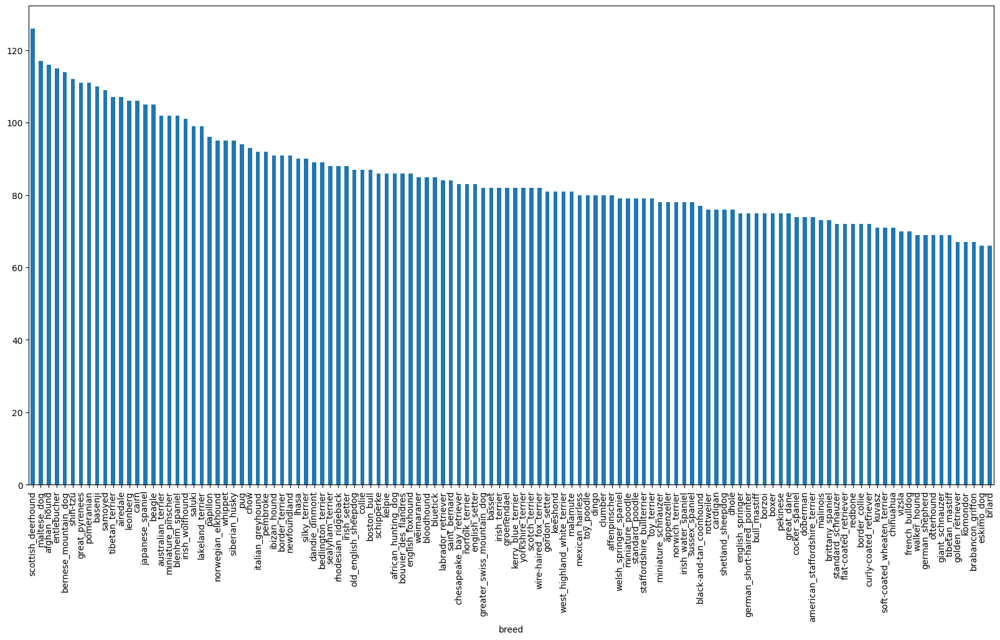

In [7]:
# How many images are there of each breed?
labels_csv["breed"].value_counts().plot.bar(figsize=(20, 10))

In [8]:
# How many images does each dog breed have on average
labels_csv['breed'].value_counts().median()

82.0

Google recomments a bare minimum of 10 images per class.
**It is recommended we use about 100 annotations per label.**

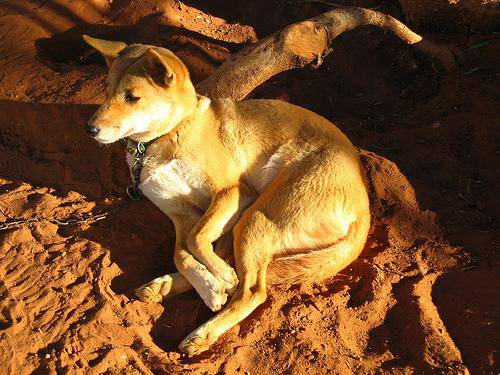

In [9]:
# Let's view an image
from IPython.display import Image
Image("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg")

### Getting images and their labels

Let's get a list of all our image file pathnames

In [10]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


In [14]:
# Create pathnames from image ID's
# paths = []

# for item in labels_csv["id"]:
#     # print(item)
#     paths.append(f"/content/drive/MyDrive/Dog Vision/train/{item}.jpg")

# Can also do it like this
filenames = ["/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/" + fname + ".jpg" for fname in labels_csv["id"]]

# Check the first 10
filenames[:10]

['/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learnin

In [15]:
# Check whether number of filenames matches number of actual image files
import os

if len(os.listdir("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/")) == len(filenames):
    print("Filenames match actual amount of files!!! Proceed.")
else:
    print("Filenames do not match actual amont of files, check the target directory")

Filenames match actual amount of files!!! Proceed.


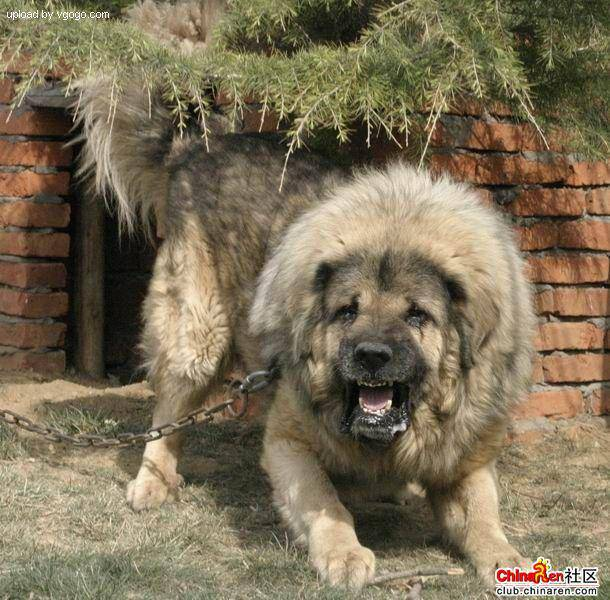

In [13]:
# One more check
Image(filenames[9000])

In [14]:
labels_csv["breed"][9000]

'tibetan_mastiff'

Since we've now got our training image filepaths in a list, let's prepare our labels.

In [16]:
import numpy as np
labels = labels_csv["breed"].to_numpy()
# labels = np.array(labels) # does same thing as above
labels

array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'], dtype=object)

In [16]:
len(labels)

10222

In [17]:
# See if number of labels matches the number of filenames
if len(labels) == len(filenames):
    print("Number of labels matches number of filenames!")
else:
    print("Number of labels does not match number of filenames, check data directories!")

Number of labels matches number of filenames!


In [17]:
# Find the unique label values
unique_breeds = np.unique(labels)
unique_breeds

array(['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale',
       'american_staffordshire_terrier', 'appenzeller',
       'australian_terrier', 'basenji', 'basset', 'beagle',
       'bedlington_terrier', 'bernese_mountain_dog',
       'black-and-tan_coonhound', 'blenheim_spaniel', 'bloodhound',
       'bluetick', 'border_collie', 'border_terrier', 'borzoi',
       'boston_bull', 'bouvier_des_flandres', 'boxer',
       'brabancon_griffon', 'briard', 'brittany_spaniel', 'bull_mastiff',
       'cairn', 'cardigan', 'chesapeake_bay_retriever', 'chihuahua',
       'chow', 'clumber', 'cocker_spaniel', 'collie',
       'curly-coated_retriever', 'dandie_dinmont', 'dhole', 'dingo',
       'doberman', 'english_foxhound', 'english_setter',
       'english_springer', 'entlebucher', 'eskimo_dog',
       'flat-coated_retriever', 'french_bulldog', 'german_shepherd',
       'german_short-haired_pointer', 'giant_schnauzer',
       'golden_retriever', 'gordon_setter', 'great_dane',
      

In [19]:
len(unique_breeds)

120

In [20]:
# Turn a single label into an array of booleans
print(labels[0])
labels[0] == unique_breeds

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [21]:
# Trun every label into a boolean array
boolean_labels = [label == unique_breeds for label in labels]
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [22]:
len(boolean_labels)

10222

In [23]:
# Example: Turning boolean array into integers
print(labels[0]) # original label
print(np.where(unique_breeds == labels[0])) # index where label occurs
print(boolean_labels[0].argmax()) # index where label occurs in boolean array
print(boolean_labels[0].astype(int)) # there will be a 1 where the sample label occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [24]:
print(labels[2])
print(boolean_labels[2].astype(int))

pekinese
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [25]:
filenames[:10]

['/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learnin

### Creating our own validation set

Since the dataset from Kaggle doesn't come with a validation set, we are going to create our own

In [26]:
# Setup X & y variables
X = filenames
y = boolean_labels

In [27]:
len(filenames)

10222

We're going to start experimenting with ~1000 images and increase as needed.

In [28]:
# Set number of images to use for experimenting
NUM_IMAGES = 1000 #@param {type:'slider', min:1000, max:10000}

In [29]:
# Let's split our data into train and validation sets
from sklearn.model_selection import train_test_split
# Split them into training and validation of total size NUM_IMAGES
X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES],
                                                  y[:NUM_IMAGES],
                                                  test_size=0.2,
                                                  random_state=42)

len(X_train), len(y_train), len(X_val), len(y_val)

(800, 800, 200, 200)

In [30]:
# Let's have a look at the training data
X_train[:5], y_train[:2]

(['/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00bee065dcec471f26394855c5c2f3de.jpg',
  '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/0d2f9e12a2611d911d91a339074c8154.jpg',
  '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/1108e48ce3e2d7d7fb527ae6e40ab486.jpg',
  '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/0dc3196b4213a2733d7f4bdcd41699d3.jpg',
  '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/146fbfac6b5b1f0de83a5d0c1b473377.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, 

## Preprocessing images (turning images into Tensors)

To preprocess our images into Tensors we're going to write a function which does a few things:
1. Take an image filepath as input
2. Use TensorFlow to read the file and save it to a variable, `image`
3. Turn our `image` (a jpg) into Tensors
4. Resize the `image` to be a shape of (224, 224)
5. Return the modified `image`

Before we do, let's see what importing an image looks like.

In [31]:
# Convert image to NumPy
from matplotlib.pyplot import imread
image = imread(filenames[777])
image.shape

(333, 441, 3)

In [32]:
image.max(), image.min()

(np.uint8(255), np.uint8(0))

In [33]:
image[:2]

array([[[ 13,  13,  15],
        [ 12,  12,  14],
        [ 11,  11,  13],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[ 15,  15,  17],
        [ 14,  14,  16],
        [ 12,  12,  14],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)

In [34]:
# Turn image into a tensor
tf.constant(image)[:2]

<tf.Tensor: shape=(2, 441, 3), dtype=uint8, numpy=
array([[[ 13,  13,  15],
        [ 12,  12,  14],
        [ 11,  11,  13],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[ 15,  15,  17],
        [ 14,  14,  16],
        [ 12,  12,  14],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)>

Now we've seen what an image looks like as a Tensor, let's make a function to preprocess them.

1. Take an image filepath as input
2. Use TensorFlow to read the file and save it to a variable, `image`
3. Turn our `image` (a jpg) into Tensors
4. Normalize our image (convert color channel values from 0-255 to 0-1)
5. Resize the `image` to be a shape of (224, 224)
6. Return the modified `image`

In [7]:
# Define image size
IMG_SIZE = 224

# Create a function for preprocessing images
def process_image(image_path, img_size=IMG_SIZE):
    """
    Takes an image file path and turns the image into a Tensor.
    """
    # Read in an image file
    image = tf.io.read_file(image_path)
    # Turn the jpeg image into numerical Tensor with 3 color channels (Red, Green, Blue)
    image = tf.image.decode_jpeg(image, channels=3)
    # Convert the color channel values from 0-255 to 0-1 values. Makes computing more efficient
    image = tf.image.convert_image_dtype(image, tf.float32)
    # Resize the image to our desired value (224, 224)
    image = tf.image.resize(image, size=[img_size, img_size])

    return image

In [36]:
image = tf.io.read_file(filenames[256]) # Turns image file into a long string
image

<tf.Tensor: shape=(), dtype=string, numpy=b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\n\x07\x07\x08\x07\x06\n\x08\x08\x08\x0b\n\n\x0b\x0e\x18\x10\x0e\r\r\x0e\x1d\x15\x16\x11\x18#\x1f%$"\x1f"!&+7/&)4)!"0A149;>>>%.DIC<H7=>;\xff\xdb\x00C\x01\n\x0b\x0b\x0e\r\x0e\x1c\x10\x10\x1c;("(;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;\xff\xc0\x00\x11\x08\x01f\x01\xf4\x03\x01"\x00\x02\x11\x01\x03\x11\x01\xff\xc4\x00\x1f\x00\x00\x01\x05\x01\x01\x01\x01\x01\x01\x00\x00\x00\x00\x00\x00\x00\x00\x01\x02\x03\x04\x05\x06\x07\x08\t\n\x0b\xff\xc4\x00\xb5\x10\x00\x02\x01\x03\x03\x02\x04\x03\x05\x05\x04\x04\x00\x00\x01}\x01\x02\x03\x00\x04\x11\x05\x12!1A\x06\x13Qa\x07"q\x142\x81\x91\xa1\x08#B\xb1\xc1\x15R\xd1\xf0$3br\x82\t\n\x16\x17\x18\x19\x1a%&\'()*456789:CDEFGHIJSTUVWXYZcdefghijstuvwxyz\x83\x84\x85\x86\x87\x88\x89\x8a\x92\x93\x94\x95\x96\x97\x98\x99\x9a\xa2\xa3\xa4\xa5\xa6\xa7\xa8\xa9\xaa\xb2\xb3\xb4\xb5\xb6\xb7\xb8\xb9\xba\xc2\xc3\xc4\xc5\xc6\xc7\xc8\xc9\xca

In [37]:
image = tf.image.decode_jpeg(image, channels=3) # Turns long string into numerical tensor
image

<tf.Tensor: shape=(358, 500, 3), dtype=uint8, numpy=
array([[[163, 125, 104],
        [157, 119,  98],
        [155, 117,  94],
        ...,
        [151, 104,  60],
        [147, 100,  56],
        [146,  99,  55]],

       [[161, 123, 102],
        [156, 118,  97],
        [156, 118,  95],
        ...,
        [153, 106,  62],
        [149, 102,  58],
        [148, 101,  57]],

       [[158, 120,  99],
        [156, 118,  97],
        [157, 119,  96],
        ...,
        [153, 109,  64],
        [149, 105,  60],
        [148, 104,  59]],

       ...,

       [[121, 103,  91],
        [119, 101,  89],
        [117,  99,  85],
        ...,
        [116,  82,  44],
        [118,  84,  46],
        [119,  85,  47]],

       [[125, 107,  95],
        [121, 103,  91],
        [117,  99,  85],
        ...,
        [115,  81,  43],
        [116,  82,  44],
        [118,  84,  46]],

       [[126, 108,  96],
        [122, 104,  92],
        [118, 100,  86],
        ...,
        [113,  79,  4

In [38]:
image = tf.image.convert_image_dtype(image, tf.float32) # Normalizes data
image

<tf.Tensor: shape=(358, 500, 3), dtype=float32, numpy=
array([[[0.6392157 , 0.4901961 , 0.40784317],
        [0.6156863 , 0.4666667 , 0.38431376],
        [0.60784316, 0.45882356, 0.36862746],
        ...,
        [0.5921569 , 0.40784317, 0.23529413],
        [0.5764706 , 0.3921569 , 0.21960786],
        [0.57254905, 0.38823533, 0.21568629]],

       [[0.6313726 , 0.48235297, 0.40000004],
        [0.6117647 , 0.46274513, 0.3803922 ],
        [0.6117647 , 0.46274513, 0.37254903],
        ...,
        [0.6       , 0.4156863 , 0.24313727],
        [0.58431375, 0.40000004, 0.227451  ],
        [0.5803922 , 0.39607847, 0.22352943]],

       [[0.61960787, 0.47058827, 0.38823533],
        [0.6117647 , 0.46274513, 0.3803922 ],
        [0.6156863 , 0.4666667 , 0.37647063],
        ...,
        [0.6       , 0.427451  , 0.2509804 ],
        [0.58431375, 0.41176474, 0.23529413],
        [0.5803922 , 0.40784317, 0.23137257]],

       ...,

       [[0.47450984, 0.4039216 , 0.35686275],
        [0.46

In [39]:
image = tf.image.resize(image, size=[IMG_SIZE, IMG_SIZE]) # Resize image
image

<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
array([[[0.6230966 , 0.47407702, 0.39172408],
        [0.62797916, 0.48228592, 0.38211083],
        [0.6351608 , 0.50574905, 0.38418043],
        ...,
        [0.56746125, 0.41685927, 0.26360297],
        [0.5978291 , 0.420168  , 0.25427157],
        [0.57731086, 0.3929972 , 0.22044814]],

       [[0.61523974, 0.4662201 , 0.38386717],
        [0.6289305 , 0.48323724, 0.38306215],
        [0.61038965, 0.4809779 , 0.35940924],
        ...,
        [0.5682476 , 0.42988184, 0.2733894 ],
        [0.6063111 , 0.43622193, 0.26680657],
        [0.5828081 , 0.40905112, 0.23298316]],

       [[0.6110052 , 0.4619856 , 0.37963265],
        [0.6262659 , 0.48448882, 0.3840188 ],
        [0.5944503 , 0.4656688 , 0.34410015],
        ...,
        [0.575652  , 0.45043913, 0.28382498],
        [0.60276604, 0.44632608, 0.27182844],
        [0.5808648 , 0.41612396, 0.2415966 ]],

       ...,

       [[0.4538959 , 0.38330764, 0.33624882],
        [0.46

## Turning our data into batches

Why turn our data into batches?
* We take a small portion of images (32 in this case) and calculate on those images at one time.

Let's say you're trying to process 10,000+ images in one go... they all might not fit into memory.

So that's why we do about 32 (this is the batch size) images at a time (you can manually adjust the batch size if need be)

In order to use TensorFlow effectively, we need our data in the form of Tensor tuples which look like this: `(image, label)`

In [40]:
# Create a simple function to return a tuple (image, label)
def get_image_label(image_path, label):
    """
    Takes an image file path name and the associated label, process the image and returns a tuple of (image, label).
    """
    image = process_image(image_path)
    return image, label

In [41]:
# Demo of the above
(process_image(X[42]), y[42])

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

In [42]:
(process_image(X[42]), tf.constant(y[42]))

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

Now we've got a way to turn our data into tuples of Tensors in the form: `(image, label)`, let's make a function to turn all our data (`X` & `y`) into batches!

In [8]:
# Define the batch size, 32 is a good start
BATCH_SIZE = 32

# Create a function to turn data into batches
def create_data_batches(X, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
    """
    Creates batches of data out of image (X) and label (y) pairs.
    Shuffles the data if it's training data but doesn't shuffle if it's validation data.
    Also accepts test data as input (no labels - this is why y can be None)
    """
    # If the data is a test dataset, we probably don't have labels
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices(tf.constant(X)) # only filepaths (no labels)
        data_batch = data.map(process_image).batch(BATCH_SIZE)
        return data_batch

    # If the data is a valid dataset, we don't need to shuffle it
    elif valid_data:
        print("Creating validation data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X), # filepaths
                                                  tf.constant(y))) # labels
        data_batch = data.map(get_image_label).batch(BATCH_SIZE)
        return data_batch

    else:
        print("Creating training data batches...")
        # Turn filepaths and labels into Tensors
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X),
                                                   tf.constant(y)))
        # Shuffling pathnames and labels before mapping image processor function is faster than shuffling images
        data = data.shuffle(buffer_size=len(X))

        # Create (image, label) tuples (this also turns the image path into a preprocessed image)
        data = data.map(get_image_label)

        # Turn the training data into batches
        data_batch = data.batch(BATCH_SIZE)
    return data_batch

In [44]:
# Create training and validation data batches
train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [45]:
# Check out different attributes of our data batches
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

## Visualizing Data Batches

Our data is now in batches, however, these can be a little hard to understand/comprehend, let's visualize them!

In [41]:
import matplotlib.pyplot as plt

# Create a function for viewing images in a data batch
def show_25_images(images, labels):
    """
    Displays a plot of 25 images and their labels from a data batch.
    """
    # Setup the figure
    plt.figure(figsize=(10,10))
    # Loop through 25 (for displaying 25 images)
    for i in range(25):
        # Create subplots (5 rows, 5 columns)
        ax = plt.subplot(5, 5, i+1)
        # Display and image
        plt.imshow(images[i])
        # Add the image label
        plt.title(unique_breeds[labels[i].argmax()])
        # Turn the grid lines off
        plt.axis("off")

In [47]:
train_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

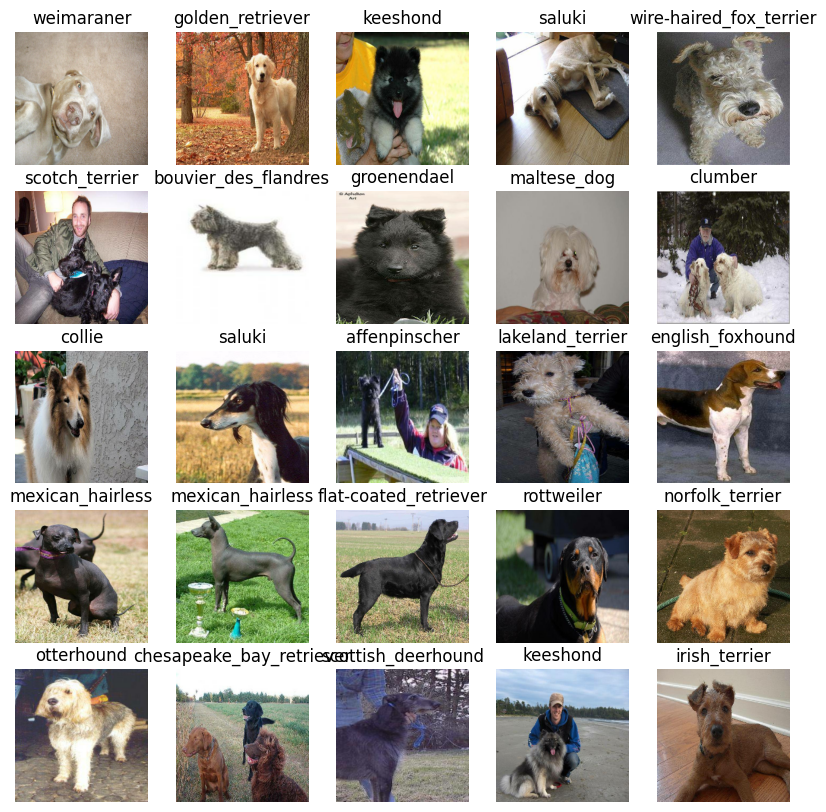

In [48]:
# Now let's visualize the data in a training batch
train_images, train_labels = next(train_data.as_numpy_iterator())
show_25_images(train_images, train_labels)

In [49]:
len(train_images), len(train_labels)

(32, 32)

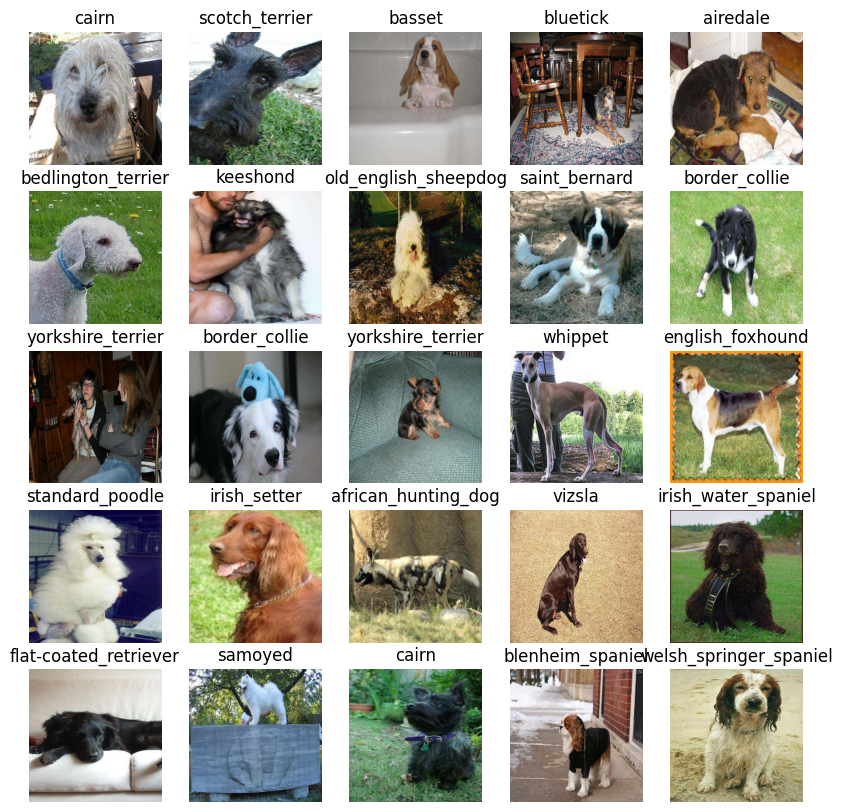

In [50]:
# Now let's visualize our valdiation set
val_images, val_labels = next(val_data.as_numpy_iterator())
show_25_images(val_images, val_labels)

## Building a Model

Before we build a model, there are a few things we need to define:
* The input shape (our images shape, in the form of Tensors) to our model.
* The output shape (image labels, in the form of Tensors) of our model.
* The URL of the model we want to use from TensorFlow hub - https://www.tensorflow.org/hub

In [19]:
# Setup input shape to the model
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE, 3] # batch, height, width, color channels

# Setup output shape of our model
OUTPUT_SHAPE = len(unique_breeds)

# Setup model URL from TensorFlow Hub - Changed to feature_vector model
MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4"

Now we've got our inputs, outputs and model ready to go.
Let's put them together into a Keras deep learning model!

Knowing this, let's create a function which:
* Takes the input shape, output shape and the model we've chosen as parameters.
* Defines the layers in a Keras model in sequential fashion (do this first, then this, then that).
* Compiles the model (says it should be evaluated and improved).
* Builds the model (tells the model the input shape it'll be getting).
* Returns the model.

All of these steps can be found here: https://www.tensorflow.org/guide/keras/overview

In [20]:
import tf_keras

# Create a function which builds a Keras model
def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
    print("Building model with:", MODEL_URL)

    # Setup the model layers
    model = tf_keras.Sequential([hub.KerasLayer(MODEL_URL), # Layer 1 (input layer)
                                 tf_keras.layers.Dense(units=OUTPUT_SHAPE,
                                 activation="softmax")]) # Layer 2 (output layer)

    # Compile the model
    model.compile(loss=tf_keras.losses.CategoricalCrossentropy(),
                  optimizer=tf_keras.optimizers.Adam(),
                  metrics=["accuracy"])

    # Build the model
    model.build(INPUT_SHAPE)

    return model

In [53]:
model = create_model()
model.summary()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1001)              5432713   
                                                                 
 dense (Dense)               (None, 120)               120240    
                                                                 
Total params: 5552953 (21.18 MB)
Trainable params: 120240 (469.69 KB)
Non-trainable params: 5432713 (20.72 MB)
_________________________________________________________________


In [54]:
outputs = np.ones(shape=(1,1, 1280))
outputs

array([[[1., 1., 1., ..., 1., 1., 1.]]])

## Creating callbacks

Callbacks are helper functions a model can use during training to do such things as save its progress, check its progress or stop training early if a model stops improving

https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/Callback

We'll create two callbakcs:
* TensorBoard - helps track our model's progress
* early stopping - prevents our model from training for too long

## TensorBoard Callback

To setup a TensorBoard callback, we need to do 3 things:
1. Load the TensorBoard notebook extension ✅
2. Create a TensorBoard callback which is able to save logs to a directory and pass it tour model's `fit()` function. ✅
3. Visualize our model's training logs with the `%tensorboard` magic function (we'll do this after model training).


In [55]:
# Load TensorBoard notebook extension
%load_ext tensorboard

In [56]:
import datetime

# Create a function to build a TensorBoard callback
def create_tensorboard_callback():
    # Create a log directory for storing TensorBoard logs
    logdir = os.path.join("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/logs",
                          # Make it so the logs get tracked whenever we run an experiment
                          datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    #return tf.keras.callbacks.TensorBoard(logdir)
    return tf_keras.callbacks.TensorBoard(logdir)

## Early Stopping Callback

Early stopping helps our model from overfitting by stopping training if a certain evaluation metric stops improving

https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/Callback

In [57]:
# Create early stopping callback
# early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy",
#                                                  patience=3)
early_stopping = tf_keras.callbacks.EarlyStopping(monitor="val_accuracy",
                                                  patience=3)

## Training a model (on a subset of data)

Our first model is only going to train on 1000 images, to make sure everything is working.

In [58]:
NUM_EPOCHS = 100 #@param {type:'slider', min:10, max:100, step:10}

In [59]:
# Check to make sure we are still running on a GPU
print('GPU', 'available (YES!!!)' if tf.config.list_physical_devices('GPU') else 'not available')

GPU available (YES!!!)


Let's create a function which trains a model

* Create a model using `create_model()`
* Setup a TensorBoard callback using `create_tensorboard_callback`
* Call the `fit()` function on our model passing it the training data, validation data, number of epochs to train for (`NUM_EPOCHS`) and the callbacks we'd like to use.
* Return the model

In [35]:
# Build a function to train and return a trained model
def train_model():
    """
    Trains a given model and returns the trained version
    """
    # Create a model
    model = create_model()

    # Create new TensorBoard session everytime we train a model
    tensorboard = create_tensorboard_callback()

    # Fit the model to the data passing it the callbacks we created
    model.fit(x=train_data,
              epochs=NUM_EPOCHS,
              validation_data=val_data,
              validation_freq=1,
              callbacks=[tensorboard, early_stopping])
    # Return the fitted model
    return model

In [82]:
# Fit the model to the data
model = train_model()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4
Epoch 1/100
25/25 [==============================] - 133s 5s/step - loss: 4.3792 - accuracy: 0.1250 - val_loss: 3.1680 - val_accuracy: 0.2700
Epoch 2/100
25/25 [==============================] - 4s 178ms/step - loss: 1.5653 - accuracy: 0.7100 - val_loss: 2.0671 - val_accuracy: 0.5300
Epoch 3/100
25/25 [==============================] - 4s 160ms/step - loss: 0.5478 - accuracy: 0.9312 - val_loss: 1.6493 - val_accuracy: 0.5950
Epoch 4/100
25/25 [==============================] - 5s 185ms/step - loss: 0.2470 - accuracy: 0.9900 - val_loss: 1.4791 - val_accuracy: 0.6100
Epoch 5/100
25/25 [==============================] - 4s 177ms/step - loss: 0.1460 - accuracy: 0.9987 - val_loss: 1.4081 - val_accuracy: 0.6200
Epoch 6/100
25/25 [==============================] - 4s 161ms/step - loss: 0.0975 - accuracy: 1.0000 - val_loss: 1.3708 - val_accuracy: 0.6250
Epoch 7/100
25/25 [==============================]

**Question:** It looks like our model is overfitting becuase it's performing far better on the training dataset than the validation dataset, what are some ways to prevent model overfitting in deep learning neural networks?

**Note:** Overfitting to begin with is a good thing! It means our model is learning!!!

**Lookup:**
- use a larger training set
- use a smaller network
- weight-sharing (as in convolutional neural networks)
- Early stopping
- Transfer Learning
- Data normalization
- Data Augmentation
- Weight Decay
- Model Averaging
- Dropout



### Checking the TensorBoard logs

The TensorBoard magic function (`%tensorboard`) will access the logs directory we created earlier and visualize its contents.

In [83]:
%tensorboard --logdir /content/drive/MyDrive/Colab\ Notebooks/Machine\ Learning\ A-Z/Dog\ Vision/logs

Output hidden; open in https://colab.research.google.com to view.

## Making and evaluating predictions using a trained model

In [84]:
val_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [36]:
# Make predictions on the validation data (not used to train on)
predictions = model.predict(val_data, verbose=1)
predictions

NameError: name 'model' is not defined

In [86]:
predictions.shape

(200, 120)

In [87]:
len(y_val)

200

In [88]:
len(unique_breeds)

120

In [89]:
predictions[0]

array([3.54169682e-03, 1.80463267e-05, 7.94202439e-04, 1.03214188e-04,
       2.52144382e-04, 2.74282556e-05, 2.18630768e-02, 7.12885987e-04,
       7.36204893e-05, 1.47583860e-03, 2.32466133e-04, 2.07788558e-04,
       7.16159775e-05, 1.24287661e-04, 2.78474559e-04, 1.04513147e-03,
       4.52836335e-04, 2.03463241e-01, 2.17780362e-05, 8.31459329e-06,
       1.98646937e-03, 2.36548411e-04, 1.56139686e-05, 3.13504459e-03,
       2.84299022e-05, 4.49658255e-04, 1.74574152e-01, 4.43445606e-05,
       1.17749698e-03, 4.84634598e-04, 6.94612609e-05, 5.98287210e-04,
       1.80294519e-04, 2.40440277e-05, 7.04163685e-05, 1.80506967e-02,
       1.55948001e-04, 7.94856343e-04, 5.14334279e-05, 6.02999717e-05,
       1.27749378e-03, 3.20311556e-05, 1.33359630e-04, 7.80325063e-05,
       5.03753035e-05, 2.56010317e-05, 5.53724822e-05, 4.76761255e-04,
       1.05322653e-03, 7.57575617e-05, 3.41920037e-04, 6.57669880e-05,
       2.14808184e-04, 4.81839270e-05, 4.73636755e-05, 5.83214096e-05,
      

In [90]:
np.sum(predictions[0])

np.float32(1.0000001)

In [91]:
# First prediction
index = 42
print(predictions[index])
print(f'Max value (probability of prediction): {np.max(predictions[index])}')
print(f'Sum: {np.sum(predictions[index])}')
print(f'Max index: {np.argmax(predictions[index])}')
print(f'Predicted label: {unique_breeds[np.argmax(predictions[index])]}')

[1.87032158e-04 2.81774028e-05 5.89361407e-05 1.99772840e-05
 3.95142287e-03 3.76166390e-05 9.64956853e-05 7.52122607e-04
 1.75797530e-02 1.47000346e-02 2.39747296e-05 1.21149515e-05
 6.04745932e-04 3.78521695e-03 1.39343075e-03 4.75523854e-03
 3.12695993e-05 1.19284865e-04 1.26066370e-04 9.40902682e-04
 4.98712725e-05 5.87331597e-04 1.37721450e-04 3.89827255e-05
 8.20954889e-03 9.05736160e-05 7.70806146e-05 3.14083067e-04
 7.93830695e-05 5.36779298e-05 9.60387697e-05 6.61688973e-05
 5.79492007e-05 8.03996954e-06 5.51790909e-05 2.50603298e-05
 5.72571989e-05 4.02139383e-04 3.35119512e-05 2.64382839e-01
 5.88941970e-04 2.85843362e-05 7.39540393e-03 6.52427934e-06
 5.25875541e-04 1.24178723e-05 2.59126915e-04 1.44607981e-03
 2.53383532e-05 5.18121407e-04 8.05894961e-05 1.86204590e-04
 7.74701708e-04 1.25902903e-03 3.75312811e-05 2.58827087e-04
 4.01973200e-04 1.35677983e-04 3.90828245e-05 2.97111601e-05
 1.54594731e-04 3.31592310e-04 1.28637712e-05 4.66368183e-05
 9.38801750e-05 1.023297

Having the above functionality is great but we want to be able to do it at scale.

And it would be even better if we could see the image the prediction is being made on!

**Note:** Prediction probabilities are also known as confidence levels.

In [37]:
# Turn prediction probabilities into their respective label (easier to understand)
def get_pred_label(prediction_probabilities):
    """
    Turns an array of prediction probabilites into a label.
    """
    return unique_breeds[np.argmax(prediction_probabilities)]

In [ ]:
# Get a predicted label based on an array of prediction probabibilities
pred_label = get_pred_label(predictions[67])
pred_label

Now since our validation data is still in a batch dataset, we'll have to unbatchify it to make prediction on teh validation images and then compare those predictions to the validation labels (truth labels).

In [93]:
val_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [94]:
# Create a function to unbatch a batch dataset
def unbatchify(data):
    """
    Takes a batched dataset of (image, label) tensors and returns separete arrays of images and labels.
    """
    images = []
    labels = []

    # Loop through unbatched data
    for image, label in data.unbatch().as_numpy_iterator():
        images.append(image)
        # labels.append(label)
        labels.append(unique_breeds[np.argmax(label)])

    return images, labels

# Unbatchify the valdiation data
val_images, val_labels = unbatchify(val_data)
val_images[0], val_labels[0]

(array([[[0.29599646, 0.43284872, 0.3056691 ],
         [0.26635826, 0.32996926, 0.22846507],
         [0.31428418, 0.27701408, 0.22934894],
         ...,
         [0.77614343, 0.82320225, 0.8101595 ],
         [0.81291157, 0.8285351 , 0.8406944 ],
         [0.8209297 , 0.8263737 , 0.8423668 ]],
 
        [[0.2344871 , 0.31603682, 0.19543913],
         [0.3414841 , 0.36560842, 0.27241898],
         [0.45016077, 0.40117094, 0.33964607],
         ...,
         [0.7663987 , 0.8134138 , 0.81350833],
         [0.7304248 , 0.75012016, 0.76590735],
         [0.74518913, 0.76002574, 0.7830809 ]],
 
        [[0.30157745, 0.3082587 , 0.21018331],
         [0.2905954 , 0.27066195, 0.18401104],
         [0.4138316 , 0.36170745, 0.2964005 ],
         ...,
         [0.79871625, 0.8418535 , 0.8606443 ],
         [0.7957738 , 0.82859945, 0.8605655 ],
         [0.75181633, 0.77904975, 0.8155256 ]],
 
        ...,
 
        [[0.9746779 , 0.9878955 , 0.9342279 ],
         [0.99153054, 0.99772066, 0.94278

In [95]:
unique_breeds[np.argmax(predictions[0])]

'irish_wolfhound'

Now We've got ways to get:
 * Prediction labels
 * Validation labels (truth labels)
 * Validation images


 Let's make some functions to make these all a bit more visual

 We'll create a function which:
  * Takes an array of prediction probabilities, an array of truth labels, and an array of images and integers. ✅
  * Convert the prediction probabilities to a predicted label. ✅
  * Plot the predicted label, its predicted probability, the truth table, and the target image on a single plot. ✅

In [96]:
def plot_pred(prediction_probabilities, labels, images, n=1):
    """
    View the prediction, ground truth, and image for sample n
    """
    pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]

    # Get the pred label
    pred_label = get_pred_label(pred_prob)

    # Plot image & remove ticks
    plt.imshow(image)
    plt.xticks([])
    plt.yticks([])

    # Change the color of the title depending on if the prediction is right or wrong
    if pred_label == true_label:
        color = "green"
    else:
        color = "red"


    # CHange plot tile to be predicted, probability of prediction and truth label
    plt.title("{} {:2.0f}% {}".format(pred_label,
                                      np.max(pred_prob)*100,
                                      true_label),
                                      color=color)

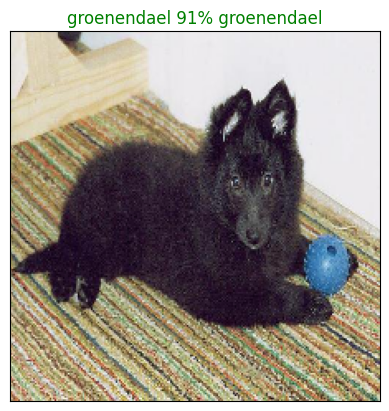

In [97]:
plot_pred(prediction_probabilities=predictions,
          labels=val_labels,
          images=val_images,
          n=77)

Now we've got one function to visualize our model's top prediction, let's make another to view our model's top 10 predictions.

This function will:
 * Take an input of prediction probabilities array and a ground truth array and an integer. ✅
 * Find the prediction using `get_pred_label()` ✅
 * Find the top 10:
    * Prediction probabilities indexes ✅
    * Prediction probabilites values ✅
    * Prediction labels ✅
 * Plot the top 10 prediction probability values and labels, coloring the true label green.✅

In [98]:
def plot_pred_conf(prediction_probabilities, labels, n=1):
    """
    Plus the top 10 highest prediction confidences along with the truth label for sample n
    """
    pred_prob, true_label = prediction_probabilities[n], labels[n]

    # Get the predicted label
    pred_label = get_pred_label(pred_prob)

    # Find the top 10 prediction confidence indexes
    top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]
    # Find the top 10 prediction confidence values
    top_10_pred_values = pred_prob[top_10_pred_indexes]
    # Find the top 10 predicition labels
    top_10_pred_labels = unique_breeds[top_10_pred_indexes]

    # Setup plot
    top_plot = plt.bar(np.arange(len(top_10_pred_labels)),
                       top_10_pred_values,
                       color="grey")
    plt.xticks(np.arange(len(top_10_pred_labels)),
               labels=top_10_pred_labels,
               rotation="vertical")

    # Change color of true label
    if np.isin(true_label, top_10_pred_labels):
        top_plot[np.argmax(top_10_pred_labels == true_label)].set_color("green")
    else:
        pass

In [99]:
# predictions[0].argsort()[::-1]
# predictions[0].argsort()[::-1]

In [100]:
# predictions[0][99], predictions[0][18], predictions[0][33], predictions[0][112], predictions[0][44]

In [101]:
# predictions[0][70], predictions[0][65], predictions[0][59], predictions[0][17], predictions[0][26]

In [102]:
# predictions[0].argsort()

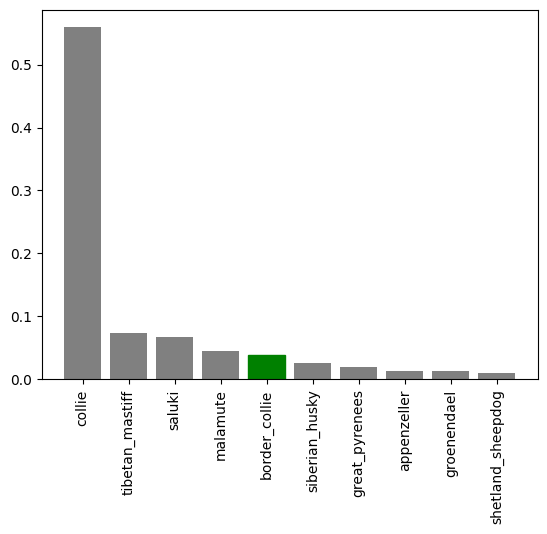

In [103]:
plot_pred_conf(prediction_probabilities=predictions,
               labels=val_labels,
               n=9)

Now we have some functions to help us visualize our predictions and evaluate our model, let's check out a few.

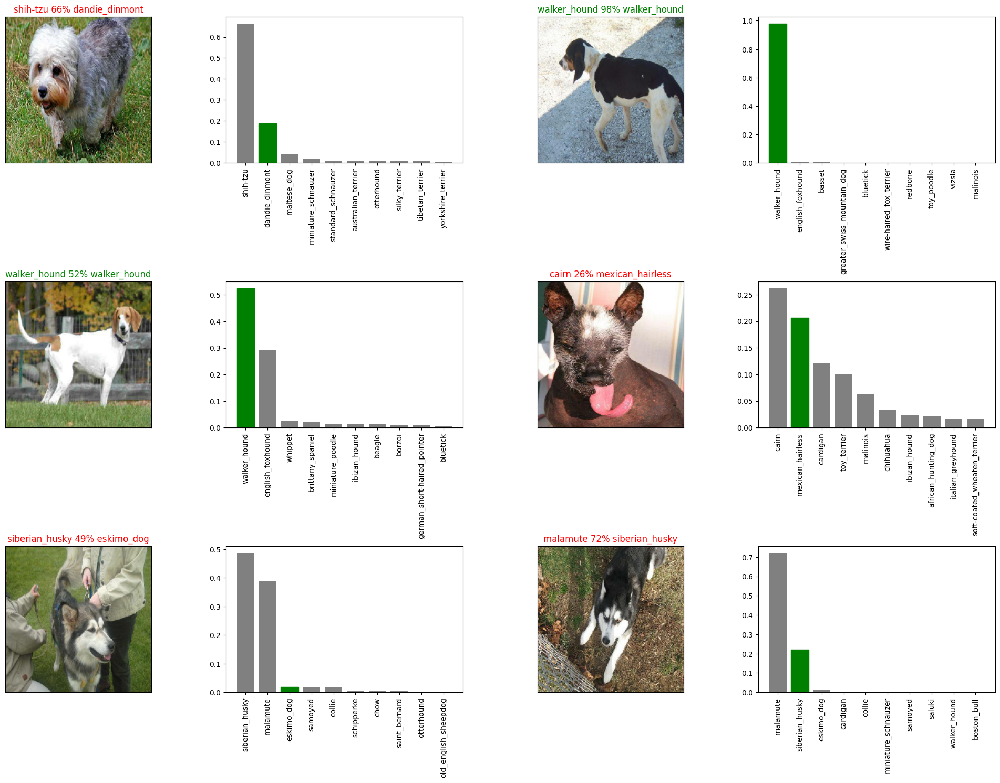

In [104]:
# Let's check out a few predictions and their different values
i_multiplier = 30
num_rows = 3
num_cols = 2
num_images = num_rows*num_cols
plt.figure(figsize=(10*num_cols, 5*num_rows))
for i in range(num_images):
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plot_pred(prediction_probabilities=predictions,
              labels=val_labels,
              images=val_images,
              n=i+i_multiplier)
    plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plot_pred_conf(prediction_probabilities=predictions,
                   labels=val_labels,
                   n=i+i_multiplier)

plt.tight_layout(h_pad=1.0)
plt.show()

**Challenge:** How would you create a confusion matrix with our models predictions and true models?

## Saving and reloading a trained model

In [105]:
# Create a function to save a model
def save_model(model, suffix=None):
    """
    Saves a given model in a models directory and appends a suffix (string)
    """
    # Create a model directory pathname with current time
    modeldir = os.path.join("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models",
                            datetime.datetime.now().strftime("%Y%m%d-%H%M%s"))
    model_path = modeldir + "-" + suffix + ".h5" # save format of model
    print(f"Saving model to: {model_path}...")
    model.save(model_path)
    return model_path

In [4]:
# Create a function to load a trained model
def load_model(model_path):
    """
    Loads a saved model from a specified path.
    """
    print(f"Loading saved model from: {model_path}")
    model = tf_keras.models.load_model(model_path,
                                       custom_objects={"KerasLayer":hub.KerasLayer})

    return model

Now we've got functions to save and load a trained model, let's make sure they work!

In [90]:
# Save our model trained on 1000 images
save_model(model, suffix="1000-images-mobilenetv2-Adam")

Saving model to: /content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-02231769048638-1000-images-mobilenetv2-Adam.h5...


'/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-02231769048638-1000-images-mobilenetv2-Adam.h5'

In [107]:
# Load a trained model
loaded_1000_image_model = load_model("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-02231769048638-1000-images-mobilenetv2-Adam.h5")

Loading saved model from: /content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-02231769048638-1000-images-mobilenetv2-Adam.h5


In [108]:
# Evaluate the pre-saved model
model.evaluate(val_data)

7/7 [==============================] - 1s 151ms/step - loss: 1.2835 - accuracy: 0.6400


[1.2835497856140137, 0.6399999856948853]

In [109]:
# Evaluate the loaded model
loaded_1000_image_model.evaluate(val_data)

7/7 [==============================] - 1s 111ms/step - loss: 1.3323 - accuracy: 0.6350


[1.3323168754577637, 0.6349999904632568]

## Training a bid god model 🐶(on the full data)

In [110]:
len(X), len(y)

(10222, 10222)

In [111]:
X[:10]

['/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learnin

In [112]:
len(X_train) # Our model has only trained in 800 images
y[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [113]:
# Create a data batch with the full data set
full_data = create_data_batches(X, y)

Creating training data batches...


In [114]:
full_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [115]:
# Create a model for full model
full_model = create_model()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4


In [116]:
# Create full model callbacks
full_model_tensorboard = create_tensorboard_callback()
# No validation set when training on all the data, so we can't monitor validation accuracy
full_model_early_stopping = tf_keras.callbacks.EarlyStopping(monitor="accuracy",
                                                             patience=3)

**Note:** Running the cell below will take a little while (maybe up to 30 minutes for the first epoch) becuase the GPU we're using in the runtime has to load all of the images into memory.

In [101]:
# Fit the full model to the full data
full_model.fit(x=full_data,
               epochs=NUM_EPOCHS,
               callbacks=[full_model_tensorboard, full_model_early_stopping])

Epoch 1/100
320/320 [==============================] - 545s 2s/step - loss: 1.3202 - accuracy: 0.6770
Epoch 2/100
320/320 [==============================] - 536s 2s/step - loss: 0.4011 - accuracy: 0.8844
Epoch 3/100
320/320 [==============================] - 527s 2s/step - loss: 0.2377 - accuracy: 0.9352
Epoch 4/100
320/320 [==============================] - 540s 2s/step - loss: 0.1524 - accuracy: 0.9627
Epoch 5/100
320/320 [==============================] - 545s 2s/step - loss: 0.1059 - accuracy: 0.9776
Epoch 6/100
320/320 [==============================] - 541s 2s/step - loss: 0.0771 - accuracy: 0.9876
Epoch 7/100
320/320 [==============================] - 527s 2s/step - loss: 0.0588 - accuracy: 0.9915
Epoch 8/100
320/320 [==============================] - 522s 2s/step - loss: 0.0448 - accuracy: 0.9950
Epoch 9/100
320/320 [==============================] - 524s 2s/step - loss: 0.0376 - accuracy: 0.9960
Epoch 10/100
320/320 [==============================] - 532s 2s/step - loss: 0.031

In [102]:
# Save our model trained on 1000 images
save_model(model, suffix="full-image-set-mobilenetv2-Adam")

Saving model to: /content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-05511769061061-full-image-set-mobilenetv2-Adam.h5...


'/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-05511769061061-full-image-set-mobilenetv2-Adam.h5'

In [24]:
# Load a trained model
loaded_full_model = load_model("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-05511769061061-full-image-set-mobilenetv2-Adam.h5")

Loading saved model from: /content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/models/20260122-05511769061061-full-image-set-mobilenetv2-Adam.h5


In [118]:
len(X)

10222

## Making predictions on the test dataset

Since our model has been trained on images in the form of Tensor batches, to make predictions on the test data, we'll have to get it into the same format.

Luckily we created `create_data_batches()` earlier which can take a alist of filenames as input and convert them into Tensor batches.

To make predictions on the test data, we'll:
* Get the test image filenames.✅
* Convert the filenames into test data batches using `create_data_batches()` and setting the `test_data` parameter to `True` (since the test data doesn't have labels).✅
* Make a predictions array by passing the test batches to the `predict()` method called on our model.✅

In [119]:
# Load test image filenames
test_path = "/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/"
test_filenames = [test_path + fname for fname in os.listdir(test_path)]
test_filenames[:10]

['/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/e6353a9420e1e529b6c20b9414786ae7.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/e48f3d4f0514a07f4777a30f01d32ea9.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/e1fa4eb8a57184773ac11efe0de11e92.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/e0c11786a50ce49abdb71397d711ecc9.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/ddf2401701ee374c0f1f9dd607071ec7.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/e7f95aabf775a636b3893ffa120adaf9.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/dff6d0e5746812e0e5808c0e69a20574.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/e721c3eec5951861bf3ed7f40ef8b091.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Do

In [120]:
len(test_filenames)

10357

In [121]:
# Create test data batch
test_data = create_data_batches(test_filenames, test_data=True)

Creating test data batches...


In [122]:
test_data

<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

**Note:** Calling `predict()` on our full model and passing it the test data batch will take a long time to run (about 1 hour)

In [123]:
# Make predictions on test data batch using the loaded full model
test_predictions = loaded_full_model.predict(test_data,
                                             verbose = 1)

324/324 [==============================] - 1826s 6s/step


In [124]:
# Save predictions (NumPy array) to csv file (for access later)
np.savetxt("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/preds_array.csv", test_predictions, delimiter=",")

In [125]:
# Load predictions (NumPy array) from csv file
test_predictions = np.loadtxt("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/preds_array.csv", delimiter=",")

In [126]:
test_predictions[:10]

array([[1.56143324e-05, 1.00194011e-03, 4.46842227e-04, ...,
        9.90259112e-04, 4.98793554e-04, 1.50004184e-04],
       [1.05005468e-03, 4.11185846e-02, 1.89079829e-02, ...,
        1.66423083e-03, 5.87761133e-05, 5.74569101e-04],
       [4.84929932e-03, 1.92037100e-04, 3.13878467e-04, ...,
        3.70885391e-05, 2.17059569e-04, 1.60979951e-04],
       ...,
       [2.88460869e-04, 2.14265543e-03, 5.91612625e-05, ...,
        4.12797381e-04, 2.35411979e-04, 2.94987956e-04],
       [3.35571094e-05, 1.79124836e-04, 3.16360354e-04, ...,
        2.17639795e-03, 1.60271360e-04, 6.47855783e-03],
       [1.46103976e-02, 7.81496128e-05, 6.64503314e-05, ...,
        1.88534847e-04, 5.46756957e-04, 1.44552335e-03]])

In [127]:
test_predictions.shape

(10357, 120)

## Preparing test dataset predictions for Kaggle

Looking at the Kaggle sample submission, we find that it wants our model's prediction probability otputs in a Dataframe with an ID and a column for each different dog breed. https://www.kaggle/com/c/dog-breed-identification/overview/evaluation

To get the data in this format, we'll:
* Create a pandas DataFrame with an ID column as well as a column for each dog breed.✅
* Add data to the ID column by extracting the test image ID's from their filepaths.✅
* Add data (the prediction probabilities) to each of the dog breed columns.✅
* Export the DataFrame as a CSV to submit it to Kaggle.✅

In [135]:
list(unique_breeds)

['affenpinscher',
 'afghan_hound',
 'african_hunting_dog',
 'airedale',
 'american_staffordshire_terrier',
 'appenzeller',
 'australian_terrier',
 'basenji',
 'basset',
 'beagle',
 'bedlington_terrier',
 'bernese_mountain_dog',
 'black-and-tan_coonhound',
 'blenheim_spaniel',
 'bloodhound',
 'bluetick',
 'border_collie',
 'border_terrier',
 'borzoi',
 'boston_bull',
 'bouvier_des_flandres',
 'boxer',
 'brabancon_griffon',
 'briard',
 'brittany_spaniel',
 'bull_mastiff',
 'cairn',
 'cardigan',
 'chesapeake_bay_retriever',
 'chihuahua',
 'chow',
 'clumber',
 'cocker_spaniel',
 'collie',
 'curly-coated_retriever',
 'dandie_dinmont',
 'dhole',
 'dingo',
 'doberman',
 'english_foxhound',
 'english_setter',
 'english_springer',
 'entlebucher',
 'eskimo_dog',
 'flat-coated_retriever',
 'french_bulldog',
 'german_shepherd',
 'german_short-haired_pointer',
 'giant_schnauzer',
 'golden_retriever',
 'gordon_setter',
 'great_dane',
 'great_pyrenees',
 'greater_swiss_mountain_dog',
 'groenendael',


In [140]:
# Create a pandas DataFrame with empty columns
preds_df = pd.DataFrame(columns=["id"] + list(unique_breeds))
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier


In [141]:
test_path

'/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/test/'

In [142]:
# Append test image ID's to predictions DataFrame
test_ids = [os.path.splitext(path)[0] for path in os.listdir(test_path)]
test_ids

['e6353a9420e1e529b6c20b9414786ae7',
 'e48f3d4f0514a07f4777a30f01d32ea9',
 'e1fa4eb8a57184773ac11efe0de11e92',
 'e0c11786a50ce49abdb71397d711ecc9',
 'ddf2401701ee374c0f1f9dd607071ec7',
 'e7f95aabf775a636b3893ffa120adaf9',
 'dff6d0e5746812e0e5808c0e69a20574',
 'e721c3eec5951861bf3ed7f40ef8b091',
 'df0196ea5d16d1570c1f2b567b975b90',
 'e79030be9c9769f3604474aea16039bd',
 'e55d2fced9eb7e46aef5bdb288145fa4',
 'e97a63b529b7b274eeb605391366b576',
 'ef627a04965eda29fc3761b1f663aef1',
 'eddf1be0c12c7f3a5029a7787e89476f',
 'f3d2b254424ab99c267abc3ab22ba627',
 'f3535f627d9d45218bd401ec24e250ac',
 'f4fa65b062607d69c98f16cb625d5915',
 'f59518330db44c70a9bad7e8a4314f3b',
 'e9615e7f30ffcf6d705ce9cbcb6d688c',
 'f53ae57b0cae92b14f87716a815d66e9',
 'f49dbff2463687f867bfe1bc88f0a7c3',
 'f00d734eff06f3a77fcc629402a95597',
 'ef59760870674327ca5d004bae427422',
 'f27521a58ff23d0bb6390bd802b368c4',
 'eabbab9c853d5b0893e45ec8fd3f97d0',
 'ed3ff512284e226da7ce2853a0faeed7',
 'f202ad1aaf619f90386d96f5b874eeef',
 

In [143]:
preds_df["id"] = test_ids

In [144]:
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,e6353a9420e1e529b6c20b9414786ae7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,e48f3d4f0514a07f4777a30f01d32ea9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,e1fa4eb8a57184773ac11efe0de11e92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,e0c11786a50ce49abdb71397d711ecc9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ddf2401701ee374c0f1f9dd607071ec7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [145]:
# Add the prediction probabilities to each dog breed column
preds_df[list(unique_breeds)] = test_predictions
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,e6353a9420e1e529b6c20b9414786ae7,0.000016,0.001002,0.000447,0.000328,0.000030,0.000440,0.000015,0.000217,0.048848,...,0.000184,0.000030,0.012550,0.000664,0.006705,0.000053,0.000035,0.000990,0.000499,0.000150
1,e48f3d4f0514a07f4777a30f01d32ea9,0.001050,0.041119,0.018908,0.000105,0.000186,0.000053,0.002142,0.000716,0.000584,...,0.000809,0.000588,0.000340,0.001782,0.000084,0.003565,0.003339,0.001664,0.000059,0.000575
2,e1fa4eb8a57184773ac11efe0de11e92,0.004849,0.000192,0.000314,0.000125,0.000036,0.000032,0.001478,0.000012,0.000106,...,0.000160,0.000111,0.000110,0.000028,0.000080,0.000075,0.023044,0.000037,0.000217,0.000161
3,e0c11786a50ce49abdb71397d711ecc9,0.003370,0.002650,0.000447,0.001424,0.002404,0.000843,0.219103,0.017933,0.000678,...,0.126083,0.000890,0.000451,0.000339,0.000112,0.024149,0.019283,0.000077,0.000002,0.055279
4,ddf2401701ee374c0f1f9dd607071ec7,0.045574,0.001841,0.000146,0.001194,0.001705,0.000166,0.001954,0.000232,0.000182,...,0.001434,0.000333,0.000082,0.000155,0.000299,0.000917,0.014601,0.000164,0.001127,0.000714


In [146]:
# Save our predictions dataframe to CSV for submission to Kaggle
preds_df.to_csv("/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/full_model_predictions_submission_1_mobilenetV2.csv",
                index=False)

## Making predictions on custom images

To make predictions on custom images, we'll:
* Get the filepaths of our own images.
* Turn the filepaths into data batches using `create_data_batches()`. And since our custom images won't have labels, we set the `test_data` parameter to `True`.
* Pass the custom image data batch to our model's `predict()` method.
* Convert the prediction output probabilities to predictions labels.
* Compare the predicted labels to the custom images.

In [25]:
# Get custom image filepaths
custom_path = "/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/"
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]

In [26]:
custom_image_paths

['/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/funny_corgi.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/australian_shepherd.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/chihuahua_hat.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/corgi.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/corgi_funny.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/australian_shep.jpg',
 '/content/drive/MyDrive/Colab Notebooks/Machine Learning A-Z/Dog Vision/my_dog_photos/chihuahua.jpg']

In [27]:
# Turn custom images into batch datasets
custom_data = create_data_batches(custom_image_paths, test_data=True)
custom_data

Creating test data batches...


<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

In [28]:
# Make predictions on the custom data
custom_preds = loaded_full_model.predict(custom_data)

1/1 [==============================] - 2s 2s/step


In [30]:
custom_preds

array([[2.86391587e-04, 4.21852528e-05, 4.77037206e-03, 7.50047984e-05,
        1.41199236e-03, 3.64334614e-04, 3.39409104e-03, 1.38981324e-02,
        1.89486818e-04, 4.11241170e-04, 8.41581495e-05, 6.07225532e-03,
        2.76262435e-04, 6.47389516e-03, 2.54117325e-03, 2.58733868e-04,
        2.20232946e-03, 4.96361265e-03, 6.93102076e-04, 3.26959393e-03,
        1.37634823e-04, 1.55719323e-03, 1.20638404e-03, 4.09731088e-04,
        6.06683781e-03, 3.74555268e-04, 4.57209477e-04, 3.42442803e-02,
        8.30397359e-04, 2.85303616e-03, 7.29462923e-03, 2.05044387e-04,
        1.00048038e-03, 3.41135962e-03, 5.59916603e-04, 7.43663346e-04,
        1.07508141e-03, 7.94522278e-03, 1.61509542e-03, 2.86483642e-04,
        3.92427959e-04, 1.86958277e-05, 3.86205240e-04, 1.50857412e-03,
        3.78401414e-03, 1.54129273e-04, 1.37500220e-03, 3.29444098e-04,
        2.98062834e-04, 8.08376819e-03, 3.06064503e-05, 1.79785828e-03,
        2.14454951e-03, 2.58237269e-04, 1.18955330e-03, 3.666765

In [31]:
custom_preds.shape # 120 prediction probs for each one

(7, 120)

In [38]:
# Get custom image prediction labels
custom_pred_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_pred_labels

['pembroke',
 'papillon',
 'japanese_spaniel',
 'pembroke',
 'pembroke',
 'welsh_springer_spaniel',
 'chihuahua']

In [39]:
# Get custom images (our unbatchify() function won't work since there aren't labels... mayve we could fix this later)
custom_images = []
# Loop through unbatched data
for image in custom_data.unbatch().as_numpy_iterator():
    custom_images.append(image)

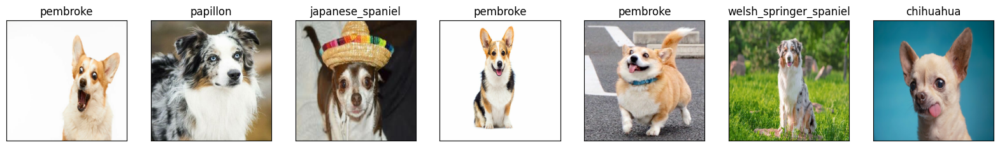

In [51]:
# Check custom image predictions
plt.figure(figsize=(20, 10))
for i, image in enumerate(custom_images):
    plt.subplot(1, 7, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.title(custom_pred_labels[i])
    plt.imshow(image)